# Infectious Waste and Properly Disposed Infectious Waste, Nonthaburi Province

**Data:** `data/raw/virusdispose.csv` — per local government per month, Buddhist Era 2563–2567 (2020–2024), with 2 indicators
- `ขยะติดเชื้อ (ตัน)` — infectious waste generated (e.g. from health facilities, face masks, ATK test kits)
- `ขยะกำจัดถูกต้อง(ตัน)` — the amount sent for proper sanitary disposal

**Steps:** load → convert numbers → fix outliers → save `clean_virusdispose.csv` → charts: trend, proper-disposal rate, by district, and number of reporting local governments

# ปริมาณขยะติดเชื้อ และขยะติดเชื้อที่กำจัดอย่างถูกต้อง จังหวัดนนทบุรี

**ข้อมูล:** `data/raw/virusdispose.csv` — ราย อปท. รายเดือน พ.ศ. 2563–2567 มี 2 ตัวชี้วัด
- `ขยะติดเชื้อ (ตัน)` — ปริมาณขยะติดเชื้อที่เกิดขึ้น (เช่น จากสถานพยาบาล, หน้ากากอนามัย, ชุดตรวจ ATK)
- `ขยะกำจัดถูกต้อง(ตัน)` — ปริมาณที่ส่งกำจัดอย่างถูกหลักสุขาภิบาล

**ขั้นตอน:** โหลด → แปลงตัวเลข → แก้ค่าผิดปกติ → บันทึก `clean_virusdispose.csv` → กราฟ: แนวโน้ม, อัตราการกำจัดถูกต้อง, รายอำเภอ และจำนวน อปท. ที่รายงานข้อมูล

**Import libraries** — `pandas` handles tabular data (DataFrame) and `numpy` handles numbers/missing values (`np.nan`)

**นำเข้าไลบรารี** — `pandas` ใช้จัดการข้อมูลแบบตาราง (DataFrame) และ `numpy` ใช้คำนวณตัวเลข/จัดการค่าว่าง (`np.nan`)

In [1]:
import pandas as pd
import numpy as np

**Load the raw data** from `../data/raw/virusdispose.csv`

**โหลดข้อมูลดิบ** จาก `../data/raw/virusdispose.csv`

In [2]:
df = pd.read_csv('../data/raw/virusdispose.csv')
df

,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะติดเชื้อ (ตัน),ขยะกำจัดถูกต้อง(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,0,0
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,0,0
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,0,0
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,0.02,0.02
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,"2,151.00","2,151.00"
...,...,...,...,...,...,...,...
2650,2567,นนทบุรี,ธันวาคม,เมืองนนทบุรี,เทศบาลเมืองไทรม้า,0,0
2651,2567,นนทบุรี,ธันวาคม,เมืองนนทบุรี,เทศบาลเมืองบางกร่าง,1.03,1.03
2652,2567,นนทบุรี,ธันวาคม,เมืองนนทบุรี,เทศบาลเมืองบางศรีเมือง,0,0
2653,2567,นนทบุรี,ธันวาคม,เมืองนนทบุรี,อบต.บางไผ่,0,0


**Check the data structure** with `df.info()` — number of rows, data types (dtype) and number of non-empty values in each column

Common issue: numeric columns with comma separators (e.g. `"1,234"`) are read as `object` (text) and must be converted to numbers before calculating

**ตรวจสอบโครงสร้างข้อมูล** ด้วย `df.info()` — ดูจำนวนแถว ชนิดข้อมูล (dtype) และจำนวนค่าที่ไม่ว่างของแต่ละคอลัมน์

สิ่งที่มักพบ: คอลัมน์ตัวเลขที่มีเครื่องหมายจุลภาค (เช่น `"1,234"`) จะถูกอ่านเป็น `object` (ข้อความ) ต้องแปลงเป็นตัวเลขก่อนนำไปคำนวณ

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   ปี                    2655 non-null   int64 
 1   เดือน                 2655 non-null   object
 2   จังหวัด               2655 non-null   object
 3   อำเภอ                 2655 non-null   object
 4   อปท                   2655 non-null   object
 5   ขยะติดเชื้อ (ตัน)     2655 non-null   object
 6   ขยะกำจัดถูกต้อง(ตัน)  2655 non-null   object
dtypes: int64(1), object(6)
memory usage: 145.3+ KB


**Data type conversion**
- Text columns with repeated values (month, province, district, local government) are converted to `category` to save memory and make `groupby` faster
- Numeric columns stored as text: remove `,` with `str.replace`, then convert to `float`
- **Fix swapped columns (2566–2567):** in the raw file 1,038 rows have the `เดือน` (month) and `จังหวัด` (province) values swapped (the month column says "นนทบุรี"), so they are swapped back before converting to `category` — without this fix the monthly charts would have no data for the last 2 years

**แปลงชนิดข้อมูล (Data type conversion)**
- คอลัมน์ข้อความที่มีค่าซ้ำ ๆ (เดือน, จังหวัด, อำเภอ, อปท) แปลงเป็น `category` เพื่อประหยัดหน่วยความจำและทำ `groupby` ได้เร็วขึ้น
- คอลัมน์ตัวเลขที่เก็บเป็นข้อความ: ลบเครื่องหมาย `,` ด้วย `str.replace` แล้วแปลงเป็น `float`
- **แก้คอลัมน์สลับกัน (ปี 2566–2567):** ในไฟล์ดิบ 1,038 แถวมีค่า `เดือน` และ `จังหวัด` สลับกัน (คอลัมน์เดือนเป็น "นนทบุรี") จึงสลับกลับก่อนแปลงเป็น `category` — ถ้าไม่แก้ กราฟรายเดือนจะไม่มีข้อมูล 2 ปีหลัง

In [4]:
# Fix swapped columns: in 2566–2567 the month and province values are swapped (month = "นนทบุรี")
# แก้คอลัมน์สลับกัน: ปี 2566–2567 ค่าในคอลัมน์ เดือน กับ จังหวัด สลับกัน (เดือน = "นนทบุรี")
swapped = df['เดือน'] == 'นนทบุรี'
df.loc[swapped, ['เดือน', 'จังหวัด']] = df.loc[swapped, ['จังหวัด', 'เดือน']].values
print(f'swapped rows fixed / แถวที่แก้: {swapped.sum()}')

for col in df.columns[1:5]:
    df[col] = df[col].astype('category')
df['ขยะติดเชื้อ (ตัน)'] = df['ขยะติดเชื้อ (ตัน)'].str.replace(',', '', regex=False).astype(float)
df['ขยะกำจัดถูกต้อง(ตัน)'] = df['ขยะกำจัดถูกต้อง(ตัน)'].str.replace(',', '', regex=False).astype(float)
df.info()

swapped rows fixed / แถวที่แก้: 1038
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2655 entries, 0 to 2654
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   ปี                    2655 non-null   int64   
 1   เดือน                 2655 non-null   category
 2   จังหวัด               2655 non-null   category
 3   อำเภอ                 2655 non-null   category
 4   อปท                   2655 non-null   category
 5   ขยะติดเชื้อ (ตัน)     2655 non-null   float64 
 6   ขยะกำจัดถูกต้อง(ตัน)  2655 non-null   float64 
dtypes: category(4), float64(2), int64(1)
memory usage: 74.9 KB


**Count missing values** in each column with `isnull().sum()` — 0 in every column means there are no gaps

This cell only shows the result of the last line (`duplicated().sum()` = number of duplicate rows) because Jupyter only displays the last expression in a cell

**นับค่าสูญหาย (Missing values)** ในแต่ละคอลัมน์ด้วย `isnull().sum()` — ถ้าเป็น 0 ทุกคอลัมน์แปลว่าไม่มีช่องว่าง

เซลล์นี้แสดงเฉพาะผลบรรทัดสุดท้าย (`duplicated().sum()` = จำนวนแถวซ้ำ) เพราะ Jupyter แสดงผลเฉพาะคำสั่งสุดท้ายของเซลล์

In [5]:
df.isnull().sum()
df.duplicated().sum()


np.int64(0)

**Back up the data before fixing outliers** — keep a copy in `df_before_clean` to compare before/after cleaning in the chart section

**สำรองข้อมูลก่อนแก้ค่าผิดปกติ** — เก็บสำเนาไว้ใน `df_before_clean` เพื่อนำไปเปรียบเทียบผลก่อน/หลังทำความสะอาดในส่วนกราฟ

In [6]:
df_before_clean = df.copy()   # kept to compare before/after fixing outliers — สำรองไว้เทียบผลก่อน/หลังแก้ค่าผิดปกติ

**Outlier treatment** for the columns `ขยะติดเชื้อ (ตัน)` and `ขยะกำจัดถูกต้อง(ตัน)`

1. Find the **median of each local government** with `groupby('อปท').transform('median')` — each one's own median is used because local governments differ greatly in size (city municipality vs subdistrict administrative organization)
2. If a month's value is **more than 10 times its own median and more than 100 tonnes**, it is treated as an outlier (usually a number typed with the wrong number of digits)
3. Replace that outlier with the local government's median

The "more than 100 tonnes" condition prevents small local governments whose normal values are near 0 from being changed unnecessarily

Finally, the helper columns (`median_...`) are removed with `df = df.drop(columns=[...])` so they don't end up in the clean file

> Fixed: this used to be `df.drop(columns=[...])` without assigning back to `df`, so the clean file kept the helper columns

**แก้ค่าผิดปกติ (Outlier treatment)** ของคอลัมน์ `ขยะติดเชื้อ (ตัน)` และ `ขยะกำจัดถูกต้อง(ตัน)`

1. หา **ค่ามัธยฐาน (median) ของแต่ละ อปท.** ด้วย `groupby('อปท').transform('median')` — ใช้ median ของตัวเองเพราะ อปท. แต่ละแห่งมีขนาดต่างกันมาก (เทศบาลนคร vs อบต.)
2. ถ้าค่าในเดือนใด **สูงกว่า 10 เท่าของ median ตัวเอง และมากกว่า 100 ตัน** ถือว่าผิดปกติ (มักเกิดจากการกรอกตัวเลขผิดหลัก)
3. แทนค่าผิดปกตินั้นด้วย median ของ อปท. นั้น

เงื่อนไข "มากกว่า 100 ตัน" ช่วยป้องกันไม่ให้ อปท. เล็ก ๆ ที่ค่าปกติใกล้ 0 ถูกแก้ค่าโดยไม่จำเป็น

สุดท้ายลบคอลัมน์ช่วยคำนวณ (`median_...`) ออกด้วย `df = df.drop(columns=[...])` เพื่อไม่ให้ติดไปในไฟล์ clean

> แก้ไขแล้ว: เดิมเขียนเป็น `df.drop(columns=[...])` โดยไม่ได้ assign กลับเข้า `df` ทำให้ไฟล์ clean มีคอลัมน์ช่วยคำนวณติดไปด้วย

In [7]:
# Fix the "ขยะติดเชื้อ (ตัน)" (infectious waste) column
# แก้คอลัมน์ "ขยะติดเชื้อ (ตัน)"
df['median_virus'] = df.groupby('อปท')['ขยะติดเชื้อ (ตัน)'].transform('median')
cond1 = (df['ขยะติดเชื้อ (ตัน)'] > df['median_virus'] * 10) & (df['ขยะติดเชื้อ (ตัน)'] > 100)
df.loc[cond1, 'ขยะติดเชื้อ (ตัน)'] = df.loc[cond1, 'median_virus']

# Fix the "ขยะกำจัดถูกต้อง(ตัน)" (properly disposed) column
# แก้คอลัมน์ "ขยะกำจัดถูกต้อง(ตัน)"
df['median_dispose'] = df.groupby('อปท')['ขยะกำจัดถูกต้อง(ตัน)'].transform('median')
cond2 = (df['ขยะกำจัดถูกต้อง(ตัน)'] > df['median_dispose'] * 10) & (df['ขยะกำจัดถูกต้อง(ตัน)'] > 100)
df.loc[cond2, 'ขยะกำจัดถูกต้อง(ตัน)'] = df.loc[cond2, 'median_dispose']

# Drop the helper median columns (only needed for the calculation above)
# ลบคอลัมน์ช่วยคำนวณ median ทิ้ง (ใช้แค่ในการคำนวณด้านบน)
df = df.drop(columns=['median_virus', 'median_dispose'])
df.head()

/var/folders/jp/qywn4qv17q56wh6qhsrjcmk80000gn/T/ipykernel_47249/2097676025.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['median_virus'] = df.groupby('อปท')['ขยะติดเชื้อ (ตัน)'].transform('median')
/var/folders/jp/qywn4qv17q56wh6qhsrjcmk80000gn/T/ipykernel_47249/2097676025.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['median_dispose'] = df.groupby('อปท')['ขยะกำจัดถูกต้อง(ตัน)'].transform('median')


,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะติดเชื้อ (ตัน),ขยะกำจัดถูกต้อง(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,0.00,0.00
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,0.00,0.00
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,0.00,0.00
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,0.02,0.02
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,0.00,0.00


**Save the cleaned data** to the `data/clean/` folder so other notebooks and the web app can use it

> Note: without `index=False` the CSV file gets a row-index column (it shows up as `Unnamed: 0` when read back)

**บันทึกข้อมูลที่ทำความสะอาดแล้ว** ลงโฟลเดอร์ `data/clean/` เพื่อให้ notebook อื่นและเว็บแอปนำไปใช้ต่อ

> หมายเหตุ: ถ้าไม่ใส่ `index=False` ไฟล์ CSV จะมีคอลัมน์ลำดับแถว (เปิดอ่านแล้วจะเห็นเป็น `Unnamed: 0`)

In [8]:
df.to_csv('../data/clean/clean_virusdispose.csv')

---
# Part 2: Data Visualization

This part turns the cleaned data into several kinds of charts to answer **"what is happening in this data"** across time (yearly/monthly), area (district/local government) and proportions

**The next cell sets up shared chart settings used by every chart:**
- Picks a **Thai font** available on the machine (Tahoma / Thonburi / Leelawadee UI, etc.) so Thai text does not turn into boxes
- Defines a **color palette (PALETTE)** tested for color-vision deficiency, and a fixed **color per district (DIST_COLOR)** — the same district has the same color in every chart and every notebook
- Creates **helper functions** `bar_labels` (numbers on bars), `stacked_bar` (stacked bar chart), `pie_chart` (pie chart)
- Creates a `viz` table, a copy of the data with category columns converted back to text so `groupby` is simple and produces no empty groups

# ส่วนที่ 2: การแสดงผลข้อมูล (Data Visualization)

ส่วนนี้นำข้อมูลที่ทำความสะอาดแล้วมาสร้างกราฟหลายรูปแบบ เพื่อตอบคำถามว่า **"เกิดอะไรขึ้นกับข้อมูลนี้"** ทั้งในมิติ เวลา (รายปี/รายเดือน) พื้นที่ (รายอำเภอ/อปท.) และสัดส่วน

**เซลล์ถัดไปเป็นการตั้งค่ากราฟที่ใช้ร่วมกันทุกกราฟ:**
- เลือก **ฟอนต์ภาษาไทย** ที่มีในเครื่อง (Tahoma / Thonburi / Leelawadee UI ฯลฯ) เพื่อไม่ให้ตัวอักษรไทยกลายเป็นสี่เหลี่ยม
- กำหนด **ชุดสี (PALETTE)** ที่ผ่านการทดสอบสำหรับผู้มีภาวะตาบอดสี และกำหนด **สีประจำอำเภอ (DIST_COLOR)** ให้คงที่ — อำเภอเดียวกันจะเป็นสีเดียวกันในทุกกราฟและทุก notebook
- สร้าง **ฟังก์ชันช่วย** `bar_labels` (ใส่ตัวเลขบนแท่ง), `stacked_bar` (กราฟแท่งซ้อน), `pie_chart` (แผนภูมิวงกลม)
- สร้างตาราง `viz` ซึ่งเป็นสำเนาของข้อมูลที่แปลงคอลัมน์ category กลับเป็นข้อความ เพื่อให้ `groupby` ทำงานง่ายและไม่เกิดกลุ่มว่าง

In [9]:
# ── Chart setup (shared by every chart in this section) ─────────────────
# ── ตั้งค่ากราฟ (ใช้ร่วมกันทุกกราฟในส่วนนี้) ─────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm, to_rgb
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# 1) Thai font: pick the first one available on this machine
# 1) ฟอนต์ภาษาไทย: เลือกตัวแรกที่มีในเครื่อง
thai_fonts = ['Tahoma', 'Thonburi', 'Leelawadee UI', 'TH Sarabun New', 'Noto Sans Thai']
available = {f.name for f in fm.fontManager.ttflist}
thai_font = next((f for f in thai_fonts if f in available), 'DejaVu Sans')
plt.rcParams.update({
    'font.family': thai_font, 'axes.unicode_minus': False,
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#bdbcb6', 'axes.labelcolor': '#52514e',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'legend.frameon': False,
})
print(f'ใช้ฟอนต์: {thai_font}')

# 2) Color palette (fixed order — checked for color-vision-deficiency separation)
# 2) ชุดสี (เรียงลำดับคงที่ — ผ่านการตรวจความแตกต่างสำหรับผู้มีภาวะตาบอดสี)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
GRAY = '#9a9992'
TEXT = '#52514e'
DIST_ORDER = ['เมืองนนทบุรี', 'บางกรวย', 'บางใหญ่', 'บางบัวทอง', 'ไทรน้อย', 'ปากเกร็ด']
DIST_COLOR = dict(zip(DIST_ORDER, PALETTE))           # color per district (fixed across all charts) — สีประจำอำเภอ (คงที่ทุกกราฟ)
MONTHS = ['มกราคม', 'กุมภาพันธ์', 'มีนาคม', 'เมษายน', 'พฤษภาคม', 'มิถุนายน',
          'กรกฎาคม', 'สิงหาคม', 'กันยายน', 'ตุลาคม', 'พฤศจิกายน', 'ธันวาคม']
MONTHS_SHORT = ['ม.ค.', 'ก.พ.', 'มี.ค.', 'เม.ย.', 'พ.ค.', 'มิ.ย.',
                'ก.ค.', 'ส.ค.', 'ก.ย.', 'ต.ค.', 'พ.ย.', 'ธ.ค.']
SEQ_CMAP = LinearSegmentedColormap.from_list('seq_blue', ['#eef4fc', '#86b6ef', '#2a78d6', '#104281'])
DIV_CMAP = LinearSegmentedColormap.from_list('div_blue_orange', ['#2a78d6', '#f0efec', '#eb6834'])
fmt_k = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}')


def bar_labels(ax, bars, fmt='{:,.0f}', horizontal=False, fontsize=9):
    """Write the value at the end of each bar — เขียนตัวเลขกำกับที่ปลายแท่ง"""
    for b in bars:
        v = b.get_width() if horizontal else b.get_height()
        if horizontal:
            ax.text(v, b.get_y() + b.get_height() / 2, '  ' + fmt.format(v),
                    va='center', ha='left', fontsize=fontsize, color=TEXT)
        else:
            ax.text(b.get_x() + b.get_width() / 2, v, fmt.format(v),
                    ha='center', va='bottom', fontsize=fontsize, color=TEXT)


def stacked_bar(ax, table, colors=None, horizontal=False):
    """Stacked bar chart: table index = main axis, columns = stacked groups; returns each bar's total — กราฟแท่งซ้อน: index ของ table = แกนหลัก, columns = กลุ่มที่ซ้อนกัน; คืนค่ายอดรวมของแต่ละแท่ง"""
    if colors is None:
        colors = [DIST_COLOR.get(c, PALETTE[i % len(PALETTE)]) for i, c in enumerate(table.columns)]
    pos = np.arange(len(table))
    base = np.zeros(len(table))
    for c, color in zip(table.columns, colors):
        vals = table[c].fillna(0).to_numpy(dtype=float)
        if horizontal:
            ax.barh(pos, vals, left=base, color=color, edgecolor='white', linewidth=1, height=0.65, label=str(c))
        else:
            ax.bar(pos, vals, bottom=base, color=color, edgecolor='white', linewidth=1, width=0.65, label=str(c))
        base += vals
    if horizontal:
        ax.set_yticks(pos, [str(i) for i in table.index]); ax.grid(axis='y', visible=False)
    else:
        ax.set_xticks(pos, [str(i) for i in table.index]); ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
    return base


def end_labels(ax, x, items, min_gap_frac=0.045):
    """Labels at the end of lines (items = [(name, y value)]) — spaced apart automatically so they do not overlap — ชื่อกำกับที่ปลายเส้น (items = [(ชื่อ, ค่า y)]) — ขยับห่างกันอัตโนมัติไม่ให้ทับกัน"""
    lo, hi = ax.get_ylim()
    gap = (hi - lo) * min_gap_frac
    items = sorted(items, key=lambda t: t[1])
    ys = [y for _, y in items]
    for i in range(1, len(ys)):
        ys[i] = max(ys[i], ys[i - 1] + gap)
    for (lab, _), y in zip(items, ys):
        ax.annotate(lab, (x, y), xytext=(8, 0), textcoords='offset points', va='center',
                    fontsize=9, color=TEXT, annotation_clip=False)


def ref_line(ax, value, label, axis='y'):
    """Reference line (average/target) with its label outside the plot area so it does not cover bars — เส้นอ้างอิง (ค่าเฉลี่ย/เป้าหมาย) พร้อมป้ายกำกับนอกพื้นที่กราฟ ไม่ทับแท่ง"""
    if axis == 'y':
        ax.axhline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(1.01, value, label, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9, color=TEXT)
    else:
        ax.axvline(value, color=TEXT, linewidth=1, linestyle='--')
        ax.text(value, 1.01, label, transform=ax.get_xaxis_transform(), va='bottom', ha='center', fontsize=9, color=TEXT)


def _ink(color):
    r, g, b = to_rgb(color)
    return '#0b0b0b' if (0.299 * r + 0.587 * g + 0.114 * b) > 0.6 else 'white'


def pie_chart(ax, values, labels, colors=None, title='', min_pct=4):
    """Pie chart: % inside slices that are big enough, name + % of every slice in the legend — แผนภูมิวงกลม: % ในชิ้นที่ใหญ่พอ, ชื่อ + % ทุกชิ้นอยู่ใน legend"""
    values = np.asarray(values, dtype=float)
    labels = [str(l) for l in labels]
    colors = colors or PALETTE[:len(values)]
    total = values.sum()
    wedges, _, autotexts = ax.pie(
        values, colors=colors, startangle=90, counterclock=False, pctdistance=0.7,
        autopct=lambda p: f'{p:.1f}%' if p >= min_pct else '',
        wedgeprops=dict(edgecolor='white', linewidth=2))
    for w, t in zip(wedges, autotexts):
        t.set_color(_ink(w.get_facecolor())); t.set_fontsize(10); t.set_fontweight('bold')
    ax.legend(wedges, [f'{l}  {v:,.0f} ({v / total * 100:.1f}%)' for l, v in zip(labels, values)],
              loc='center left', bbox_to_anchor=(1, 0.5), fontsize=10)
    ax.set_title(title)
    ax.axis('equal')

ใช้ฟอนต์: Tahoma


In [10]:
# Copy of the data for charting: convert category → text (does not affect the original table)
# สำเนาข้อมูลสำหรับทำกราฟ: แปลง category → ข้อความ (ไม่กระทบตารางต้นฉบับ)
viz = df.copy()
for c in viz.select_dtypes('category').columns:
    viz[c] = viz[c].astype(str)
viz = viz.loc[:, ~viz.columns.str.startswith(('median', 'Unnamed'))]   # drop helper columns — ตัดคอลัมน์ช่วยคำนวณ
print(viz.shape)
viz.head()

(2655, 7)


,ปี,เดือน,จังหวัด,อำเภอ,อปท,ขยะติดเชื้อ (ตัน),ขยะกำจัดถูกต้อง(ตัน)
0,2563,มกราคม,นนทบุรี,ไทรน้อย,เทศบาลตำบลไทรน้อย,0.00,0.00
1,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ขุนศรี,0.00,0.00
2,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.คลองขวาง,0.00,0.00
3,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ทวีวัฒนา,0.02,0.02
4,2563,มกราคม,นนทบุรี,ไทรน้อย,อบต.ไทรน้อย,0.00,0.00


### 2.1 Paired bar chart: infectious waste generated vs properly disposed (yearly)
**How to read it:** gray bars = amount generated, blue bars = properly disposed. If the blue bar is lower than the gray bar, some infectious waste was **not disposed of properly** (a public-health risk)

Note the period 2564–2565 (2021–2022), which coincides with the COVID-19 pandemic

### 2.1 กราฟแท่งคู่: ขยะติดเชื้อที่เกิดขึ้น vs ที่กำจัดถูกต้อง (รายปี)
**วิธีอ่าน:** แท่งเทา = ปริมาณที่เกิดขึ้น, แท่งน้ำเงิน = ที่กำจัดถูกต้อง ถ้าแท่งน้ำเงินต่ำกว่าแท่งเทา แปลว่ามีขยะติดเชื้อบางส่วน **ไม่ได้กำจัดถูกวิธี** (ความเสี่ยงด้านสาธารณสุข)

สังเกตช่วงปี 2564–2565 ซึ่งตรงกับการระบาดของโควิด-19

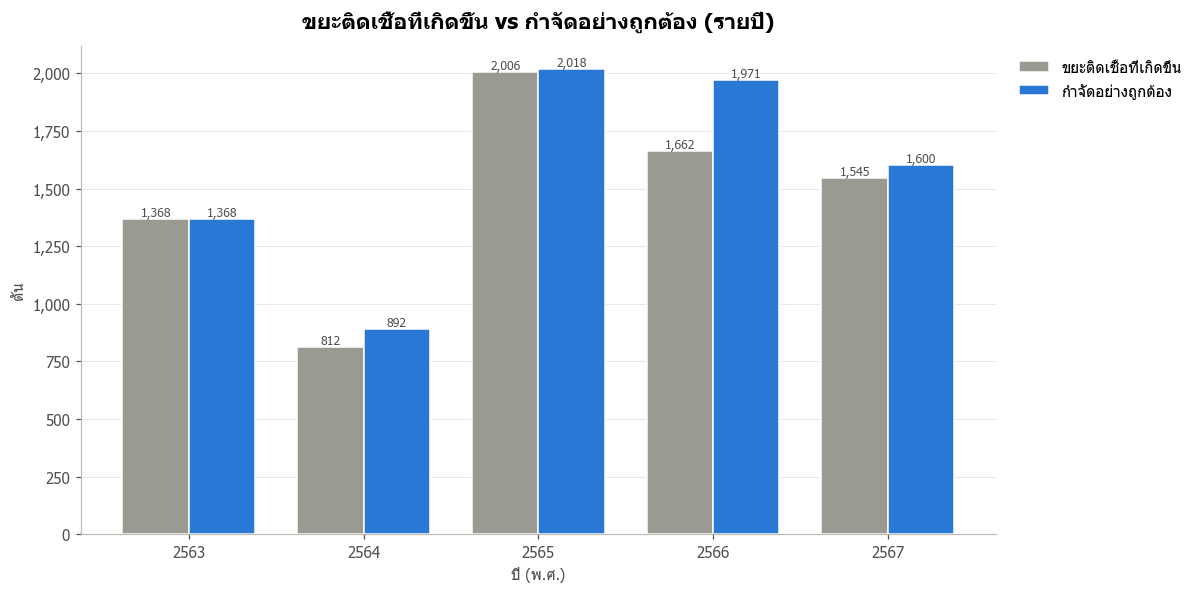

,ขยะติดเชื้อ (ตัน),ขยะกำจัดถูกต้อง(ตัน)
ปี,,
2563,1367.5,1368.0
2564,812.4,892.2
2565,2005.5,2018.2
2566,1662.4,1970.7
2567,1544.8,1600.2


In [11]:
yearly = viz.groupby('ปี')[['ขยะติดเชื้อ (ตัน)', 'ขยะกำจัดถูกต้อง(ตัน)']].sum()
x = np.arange(len(yearly)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 5.5))
b1 = ax.bar(x - w / 2, yearly['ขยะติดเชื้อ (ตัน)'], width=w, color=GRAY, label='ขยะติดเชื้อที่เกิดขึ้น', edgecolor='white', linewidth=1)
b2 = ax.bar(x + w / 2, yearly['ขยะกำจัดถูกต้อง(ตัน)'], width=w, color=PALETTE[0], label='กำจัดอย่างถูกต้อง', edgecolor='white', linewidth=1)
bar_labels(ax, b1, fontsize=8); bar_labels(ax, b2, fontsize=8)
ax.set_xticks(x, yearly.index)
ax.yaxis.set_major_formatter(fmt_k); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ขยะติดเชื้อที่เกิดขึ้น vs กำจัดอย่างถูกต้อง (รายปี)')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()
yearly.round(1)

### 2.2 Line chart: monthly trend (60 months)
**What it does:** orders the data in time (year-month) and plots both indicators on the same axis (both in tonnes)

**How to read it:** peaks are months with a lot of infectious waste. If the blue line (properly disposed) separates from the gray line, disposal in that month was late/incomplete

### 2.2 กราฟเส้น: แนวโน้มรายเดือน (60 เดือน)
**ทำอะไร:** เรียงข้อมูลตามลำดับเวลา (ปี-เดือน) แล้ววาดทั้ง 2 ตัวชี้วัดบนแกนเดียวกัน (หน่วยตันเหมือนกัน)

**วิธีอ่าน:** ช่วงที่เส้นพุ่งสูงคือเดือนที่มีขยะติดเชื้อมาก ถ้าเส้นน้ำเงิน (กำจัดถูกต้อง) แยกห่างจากเส้นเทา แปลว่าเดือนนั้นการกำจัดไม่ทัน/ไม่ครบ

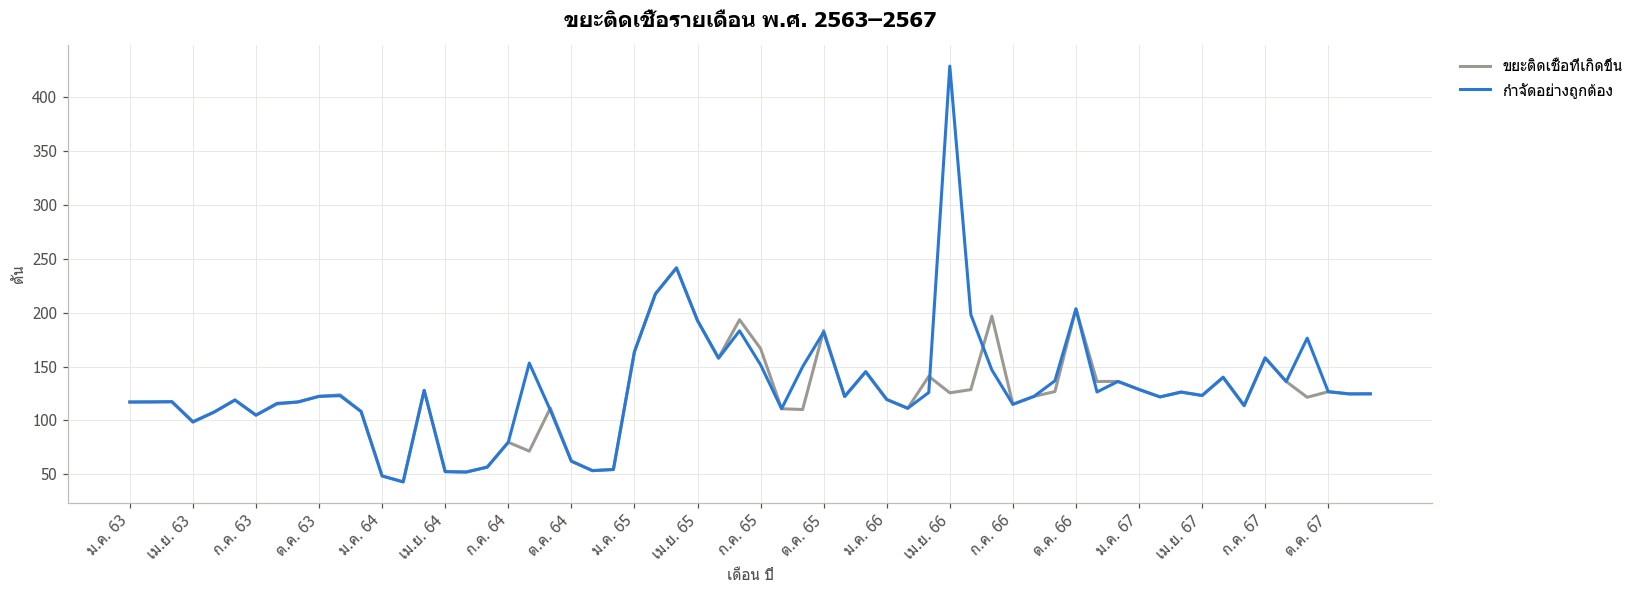

เดือนที่มีขยะติดเชื้อสูงสุด: มีนาคม 2565 = 241.7 ตัน


In [12]:
viz['เดือนที่'] = viz['เดือน'].map({m: i + 1 for i, m in enumerate(MONTHS)})
ts = viz.groupby(['ปี', 'เดือนที่'])[['ขยะติดเชื้อ (ตัน)', 'ขยะกำจัดถูกต้อง(ตัน)']].sum().sort_index()
labels = [f'{MONTHS_SHORT[m - 1]} {str(y)[-2:]}' for y, m in ts.index]
pos = np.arange(len(ts))
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(pos, ts['ขยะติดเชื้อ (ตัน)'], color=GRAY, linewidth=2, label='ขยะติดเชื้อที่เกิดขึ้น')
ax.plot(pos, ts['ขยะกำจัดถูกต้อง(ตัน)'], color=PALETTE[0], linewidth=2, label='กำจัดอย่างถูกต้อง')
ax.set_xticks(pos[::3], labels[::3], rotation=45, ha='right')
ax.yaxis.set_major_formatter(fmt_k)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ขยะติดเชื้อรายเดือน พ.ศ. 2563–2567')
ax.set_xlabel('เดือน ปี'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()
peak = ts['ขยะติดเชื้อ (ตัน)'].idxmax()
print(f"เดือนที่มีขยะติดเชื้อสูงสุด: {MONTHS[peak[1] - 1]} {peak[0]} = {ts['ขยะติดเชื้อ (ตัน)'].max():,.1f} ตัน")

### 2.3 Bar chart: proper-disposal rate (%) per year
**What it does:** `rate = properly disposed ÷ generated × 100` — the dashed line is the 100% target

**How to read it:** below 100% = some infectious waste was not disposed of properly. **Above 100%** usually does not mean better performance; it signals that the two columns were recorded inconsistently (e.g. disposing of waste left over from the previous month, or accepting waste from outside the area)

### 2.3 กราฟแท่ง: อัตราการกำจัดอย่างถูกต้อง (%) รายปี
**ทำอะไร:** `อัตรา = กำจัดถูกต้อง ÷ ที่เกิดขึ้น × 100` — เส้นประคือเป้าหมาย 100%

**วิธีอ่าน:** ต่ำกว่า 100% = ยังมีขยะติดเชื้อที่ไม่ได้กำจัดถูกวิธี, **สูงกว่า 100%** มักไม่ได้แปลว่าดีขึ้น แต่เป็นสัญญาณว่าข้อมูลสองคอลัมน์บันทึกไม่สอดคล้องกัน (เช่น กำจัดขยะค้างจากเดือนก่อน หรือรับขยะจากนอกพื้นที่)

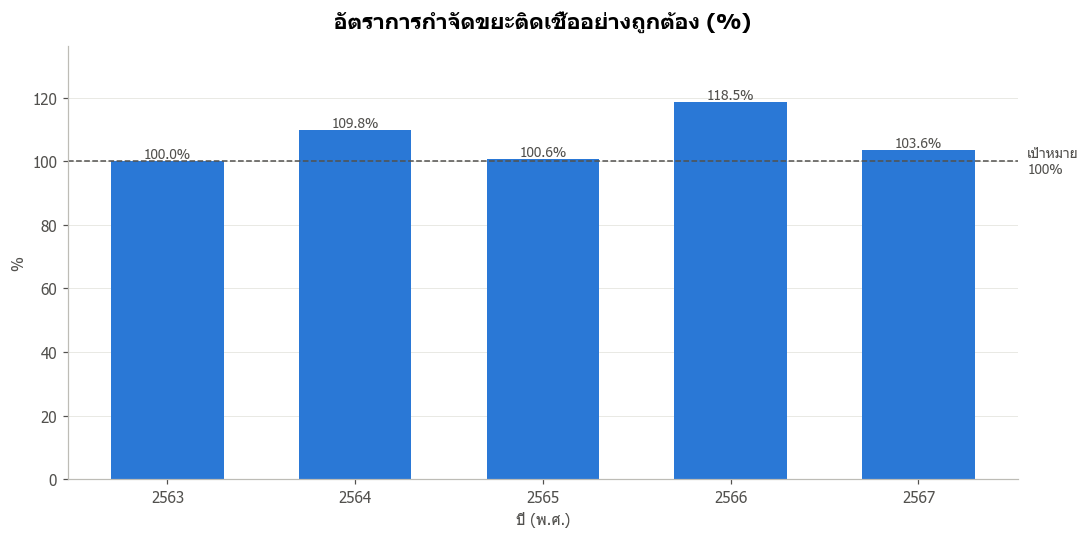

In [13]:
yearly = viz.groupby('ปี')[['ขยะติดเชื้อ (ตัน)', 'ขยะกำจัดถูกต้อง(ตัน)']].sum()
rate = yearly['ขยะกำจัดถูกต้อง(ตัน)'] / yearly['ขยะติดเชื้อ (ตัน)'] * 100
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(rate.index.astype(str), rate.values, color=PALETTE[0], width=0.6)
bar_labels(ax, bars, fmt='{:.1f}%')
ref_line(ax, 100, 'เป้าหมาย\n100%')
ax.set_ylim(0, max(rate.max(), 100) * 1.15); ax.grid(axis='x', visible=False)
ax.set_title('อัตราการกำจัดขยะติดเชื้ออย่างถูกต้อง (%)')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('%')
plt.tight_layout(); plt.show()

### 2.4 Paired bar + pie chart: by district (5 years combined)
**How to read it:** left — compares generated and properly disposed amounts in each district; right — each district's share of the province's infectious waste (districts with large hospitals usually have higher shares)

### 2.4 กราฟแท่งคู่ + แผนภูมิวงกลม: รายอำเภอ (รวม 5 ปี)
**วิธีอ่าน:** ซ้าย — เทียบปริมาณที่เกิดขึ้นกับที่กำจัดถูกต้องในแต่ละอำเภอ, ขวา — สัดส่วนขยะติดเชื้อของแต่ละอำเภอต่อทั้งจังหวัด (อำเภอที่มีโรงพยาบาลใหญ่มักมีสัดส่วนสูง)

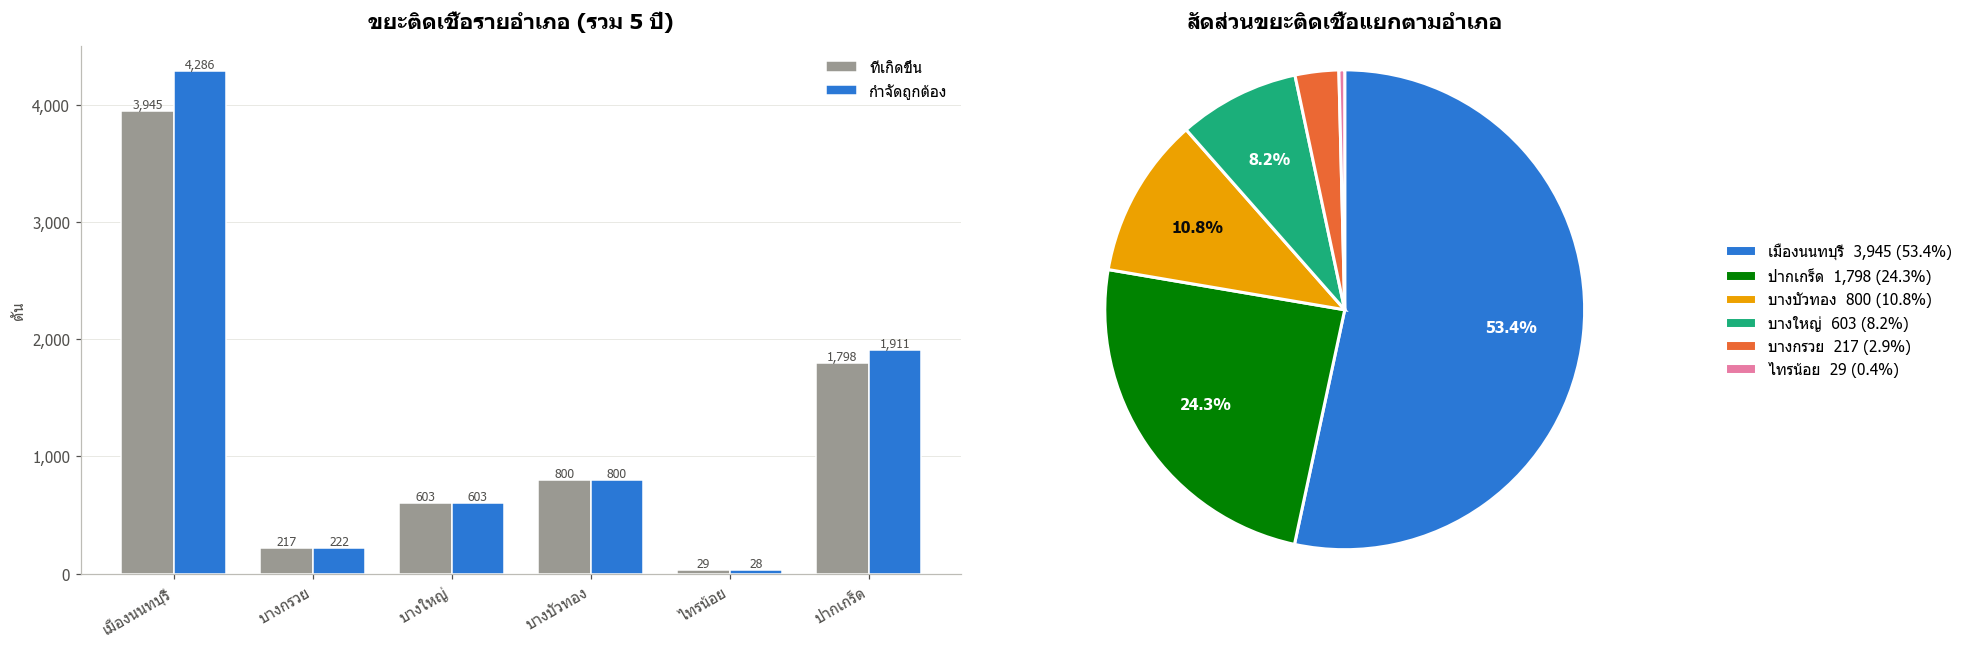

In [14]:
by_dist = viz.groupby('อำเภอ')[['ขยะติดเชื้อ (ตัน)', 'ขยะกำจัดถูกต้อง(ตัน)']].sum().reindex([d for d in DIST_ORDER if d in set(viz['อำเภอ'])])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1.2, 1]})
x = np.arange(len(by_dist)); w = 0.38
b1 = ax1.bar(x - w / 2, by_dist['ขยะติดเชื้อ (ตัน)'], width=w, color=GRAY, label='ที่เกิดขึ้น', edgecolor='white', linewidth=1)
b2 = ax1.bar(x + w / 2, by_dist['ขยะกำจัดถูกต้อง(ตัน)'], width=w, color=PALETTE[0], label='กำจัดถูกต้อง', edgecolor='white', linewidth=1)
bar_labels(ax1, b1, fontsize=8); bar_labels(ax1, b2, fontsize=8)
ax1.set_xticks(x, by_dist.index, rotation=30, ha='right')
ax1.yaxis.set_major_formatter(fmt_k); ax1.grid(axis='x', visible=False); ax1.legend()
ax1.set_title('ขยะติดเชื้อรายอำเภอ (รวม 5 ปี)'); ax1.set_ylabel('ตัน')

share = by_dist['ขยะติดเชื้อ (ตัน)'][by_dist['ขยะติดเชื้อ (ตัน)'] > 0].sort_values(ascending=False)
pie_chart(ax2, share.values, share.index, colors=[DIST_COLOR[d] for d in share.index],
          title='สัดส่วนขยะติดเชื้อแยกตามอำเภอ')
plt.tight_layout(); plt.show()

### 2.5 Data quality: number of local governments reporting infectious waste (> 0) each year
**Why it matters:** the basic statistics show a median of 0, meaning most local governments **did not report** or have no infectious waste. If the number of reporting local governments changes a lot from year to year, comparing totals across years can be misleading

### 2.5 คุณภาพข้อมูล: จำนวน อปท. ที่รายงานขยะติดเชื้อ (> 0) ในแต่ละปี
**ทำไมสำคัญ:** จากสถิติเบื้องต้น ค่ามัธยฐานของข้อมูลเป็น 0 แปลว่า อปท. ส่วนใหญ่ **ไม่ได้รายงาน** หรือไม่มีขยะติดเชื้อ ถ้าจำนวน อปท. ที่รายงานเปลี่ยนไปมากในแต่ละปี การเปรียบเทียบยอดรวมข้ามปีจะคลาดเคลื่อนได้

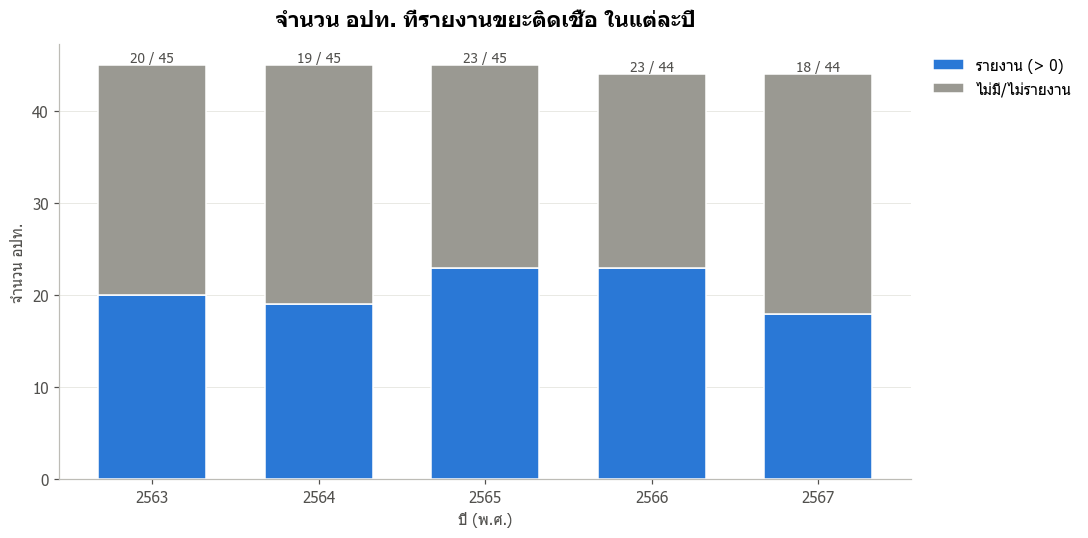

In [15]:
reporting = pd.DataFrame({
    'รายงาน (> 0)': viz[viz['ขยะติดเชื้อ (ตัน)'] > 0].groupby('ปี')['อปท'].nunique(),
    'ไม่มี/ไม่รายงาน': viz.groupby('ปี')['อปท'].nunique() - viz[viz['ขยะติดเชื้อ (ตัน)'] > 0].groupby('ปี')['อปท'].nunique(),
}).fillna(0)
fig, ax = plt.subplots(figsize=(10, 5))
totals = stacked_bar(ax, reporting, colors=[PALETTE[0], GRAY])
for i, (t, r) in enumerate(zip(totals, reporting.iloc[:, 0])):
    ax.text(i, t, f'{r:.0f} / {t:.0f}', ha='center', va='bottom', fontsize=9, color=TEXT)
ax.set_title('จำนวน อปท. ที่รายงานขยะติดเชื้อ ในแต่ละปี')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('จำนวน อปท.')
plt.tight_layout(); plt.show()

### Paired bar chart: effect of fixing outliers (before vs after cleaning)
**What it does:** compares the yearly totals of the data **before** fixing outliers (the saved copy `df_before_clean`) with the data **after** fixing them

**How to read it:** if the two bars differ a lot, that year had outliers (e.g. numbers typed with the wrong number of digits) that were replaced with the median — this shows how much cleaning changes the analysis

### กราฟแท่งคู่: ผลของการแก้ค่าผิดปกติ (ก่อน vs หลังทำความสะอาด)
**ทำอะไร:** เทียบยอดรวมรายปีระหว่างข้อมูล **ก่อน** แก้ค่าโดด (`df_before_clean` ที่สำรองไว้) กับ **หลัง** แก้

**วิธีอ่าน:** ถ้าแท่งสองสีต่างกันมาก แปลว่าปีนั้นมีค่าผิดปกติ (เช่น พิมพ์ตัวเลขผิดหลัก) ที่ถูกแทนด้วยค่ามัธยฐาน — ทำให้เห็นว่าการทำความสะอาดมีผลต่อผลวิเคราะห์มากแค่ไหน

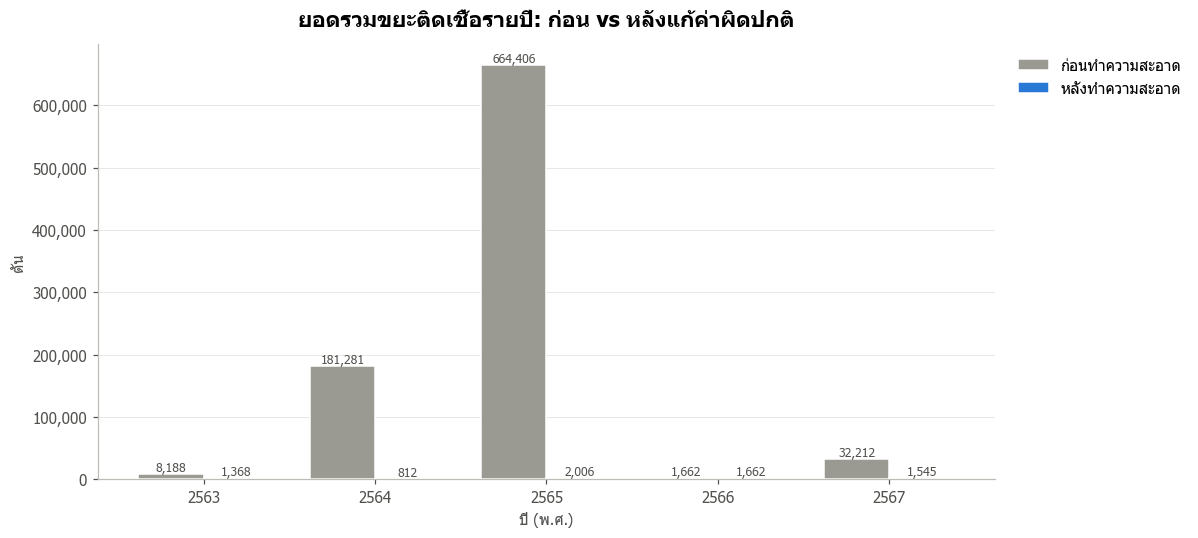

จำนวนแถวที่ถูกแก้ค่า: 16 แถว


,ก่อนทำความสะอาด,หลังทำความสะอาด,ส่วนต่าง
ปี,,,
2563,8188.3,1367.5,6820.8
2564,181281.0,812.4,180468.6
2565,664405.5,2005.5,662400.0
2566,1662.4,1662.4,0.0
2567,32211.8,1544.8,30667.0


In [16]:
col = 'ขยะติดเชื้อ (ตัน)'
compare = pd.DataFrame({
    'ก่อนทำความสะอาด': df_before_clean.groupby('ปี')[col].sum(),
    'หลังทำความสะอาด': viz.groupby('ปี')[col].sum(),
})
x = np.arange(len(compare)); w = 0.38

fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w / 2, compare.iloc[:, 0], width=w, color=GRAY, label=compare.columns[0], edgecolor='white', linewidth=1)
b2 = ax.bar(x + w / 2, compare.iloc[:, 1], width=w, color=PALETTE[0], label=compare.columns[1], edgecolor='white', linewidth=1)
bar_labels(ax, b1, fontsize=8); bar_labels(ax, b2, fontsize=8)
ax.set_xticks(x, compare.index)
ax.yaxis.set_major_formatter(fmt_k); ax.grid(axis='x', visible=False)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('ยอดรวมขยะติดเชื้อรายปี: ก่อน vs หลังแก้ค่าผิดปกติ')
ax.set_xlabel('ปี (พ.ศ.)'); ax.set_ylabel('ตัน')
plt.tight_layout(); plt.show()

n_fixed = (df_before_clean[col] != df[col]).sum()
print(f'จำนวนแถวที่ถูกแก้ค่า: {n_fixed} แถว')
compare.assign(ส่วนต่าง=compare.iloc[:, 0] - compare.iloc[:, 1]).round(1)

---
## Key Findings

1. **Infectious waste peaked in 2565 (2022, ~2,006 tonnes)**, during the COVID-19 pandemic (masks, ATK test kits), and stayed above the 2563 level in the following years
2. **The proper-disposal rate is 100–118% every year** — no year with incomplete disposal, but values above 100% (e.g. 118.5% in 2566) show the two columns were recorded inconsistently; this should be checked with the agency
3. **Mueang Nonthaburi has ~53% of the province's infectious waste**, followed by Pak Kret (~24%) — consistent with where the large hospitals are
4. **Data quality:** most local governments report 0, and the month/province columns are swapped in 2566–2567 (fixed in the cleaning step; the clean file is now correct)

## สรุปข้อค้นพบ

1. **ขยะติดเชื้อสูงสุดในปี 2565 (~2,006 ตัน)** ตรงกับช่วงการระบาดของโควิด-19 (หน้ากาก, ชุดตรวจ ATK) และยังสูงกว่าปี 2563 ในปีต่อ ๆ มา
2. **อัตรากำจัดถูกต้องอยู่ที่ 100–118% ทุกปี** — ไม่มีปีที่กำจัดไม่ครบ แต่ค่าที่เกิน 100% (เช่น 118.5% ในปี 2566) แสดงว่าสองคอลัมน์บันทึกไม่สอดคล้องกัน ควรตรวจสอบกับหน่วยงาน
3. **อำเภอเมืองนนทบุรีมีขยะติดเชื้อ ~53%** ของทั้งจังหวัด ตามด้วยปากเกร็ด (~24%) — สอดคล้องกับที่ตั้งของโรงพยาบาลขนาดใหญ่
4. **คุณภาพข้อมูล:** อปท. ส่วนใหญ่รายงานเป็น 0 และพบคอลัมน์ เดือน/จังหวัด สลับกันในปี 2566–2567 (แก้แล้วในขั้นทำความสะอาด ไฟล์ clean ถูกต้องแล้ว)